# 2. Higher-order models: AR(p)

The AR(p) model is

$$x_t = \sum_{k=1}^{p} \varphi_k\, x_{t-k} + \epsilon_t$$

and has $p$ poles.  A real pole is an exponential decay, as in AR(1).  A pair
of complex-conjugate poles is a damped oscillation, with an envelope decay and
a frequency.  An AR(1) model has one real pole and so represents one decay and
no oscillation.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from timescales import ARACF, ARPSD, compute_acf, compute_psd
from timescales.sim import AR1, AR2Damped, ARpModes

plt.rcParams.update({'figure.figsize': (10, 3.5), 'font.size': 11})
fs = 500.

## A damped oscillation as AR(2)

`AR2Damped` has one conjugate pair.  Its autocorrelation is a cosine with an
exponentially decaying envelope, and its spectrum has a peak of finite
width.

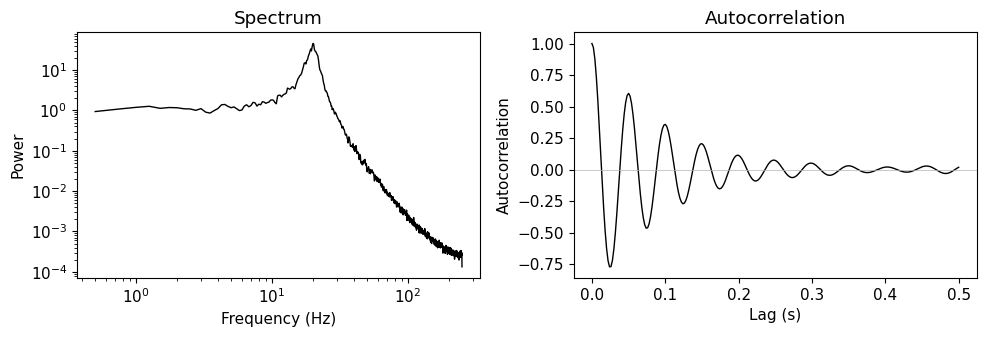

In [2]:
osc = AR2Damped(tau=0.1, f_osc=20.)      # 20 Hz, envelope decays in 100 ms
sig = osc.simulate(200., fs, np.random.default_rng(0))

freqs, powers = compute_psd(sig, fs, nperseg=int(4 * fs), f_range=(0.5, 250))
lags, corrs = compute_acf(sig, nlags=250)

fig, axes = plt.subplots(1, 2)
axes[0].loglog(freqs, powers, 'k', lw=1)
axes[0].set(xlabel='Frequency (Hz)', ylabel='Power', title='Spectrum')
axes[1].plot(lags / fs, corrs, 'k', lw=1)
axes[1].axhline(0, color='.7', lw=.5)
axes[1].set(xlabel='Lag (s)', ylabel='Autocorrelation', title='Autocorrelation')
fig.tight_layout();

## AR(1) and AR(2) fits to an AR(2) process

The same spectrum is fit at order 1 and order 2.  The AR(1) spectrum has no
peak at any parameter value.

AR(1):  R^2 = 0.7105
AR(2):  R^2 = 0.9987


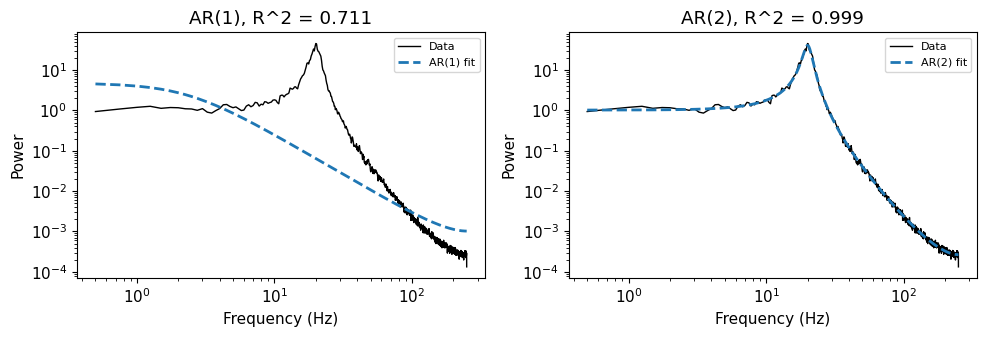

In [3]:
one = ARPSD(order=1, fs=fs).fit(freqs, powers)
two = ARPSD(order=2, fs=fs).fit(freqs, powers)

print(f'AR(1):  R^2 = {one.rsq:.4f}')
print(f'AR(2):  R^2 = {two.rsq:.4f}')

fig, axes = plt.subplots(1, 2)
one.plot(ax=axes[0], title=f'AR(1), R^2 = {one.rsq:.3f}')
two.plot(ax=axes[1], title=f'AR(2), R^2 = {two.rsq:.3f}')
fig.tight_layout();

## Order selection

An iterable passed as `order` fits each order in turn and keeps the one with
the lowest BIC.  Only the orders passed are tried.

BIC over AR order is not unimodal.  A rhythm needs several poles before any of
them pays for its penalty, so the criterion can sit on a local minimum for
many orders and then fall sharply.  A grid that ends before that happens
returns the local minimum.  `order_at_ceiling_` is True when the selected
order is the largest offered, and a warning is raised, both meaning the grid
should be extended and the fit repeated.

selected order 2, R^2 = 0.9987


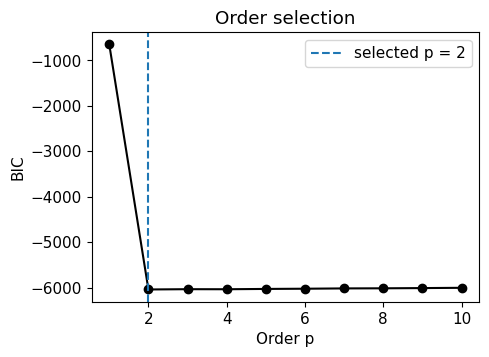

In [4]:
ar = ARPSD(order=range(1, 11), fs=fs).fit(freqs, powers)
print(f'selected order {ar.order_}, R^2 = {ar.rsq:.4f}')

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(list(ar.orders_), ar.order_scores_, 'o-', color='k')
ax.axvline(ar.order_, color='C0', ls='--', label=f'selected p = {ar.order_}')
ax.set(xlabel='Order p', ylabel='BIC', title='Order selection')
ax.legend();

BIC treats the fitted points as independent.  Welch bins from overlapping
segments are correlated, so on a dense linear frequency grid BIC selects a
higher order than the data support.  Thinning to log-spaced bins reduces the
number of correlated points.

In [5]:
keep = np.unique(np.searchsorted(
    freqs, np.logspace(np.log10(freqs[0]), np.log10(freqs[-1]), 150)))
keep = keep[keep < len(freqs)]
thinned = ARPSD(order=range(1, 11), fs=fs).fit(freqs[keep], powers[keep])
print(f'all {len(freqs)} bins      -> order {ar.order_}')
print(f'{len(keep)} log-spaced bins -> order {thinned.order_}')

all 999 bins      -> order 2
113 log-spaced bins -> order 2


## Multiple timescales

`ARpModes` constructs a process from `(tau, frequency)` pairs.  A zero
frequency gives a real pole and a non-zero frequency gives a conjugate pair.
The process below has two decays and one oscillation, so its order is 4.

In [6]:
proc = ARpModes(modes=((0.2, 0.), (0.02, 0.), (0.05, 30.)))
sig = proc.simulate(300., fs, np.random.default_rng(1))
freqs, powers = compute_psd(sig, fs, nperseg=int(4 * fs), f_range=(0.5, 250))

fits = {p: ARPSD(order=p, fs=fs).fit(freqs, powers) for p in (1, 2, 4, 8)}
for p, fit in fits.items():
    print(f'AR({p}):  R^2 = {fit.rsq:.4f}')

AR(1):  R^2 = 0.4837
AR(2):  R^2 = 0.7890
AR(4):  R^2 = 0.9998
AR(8):  R^2 = 0.9998


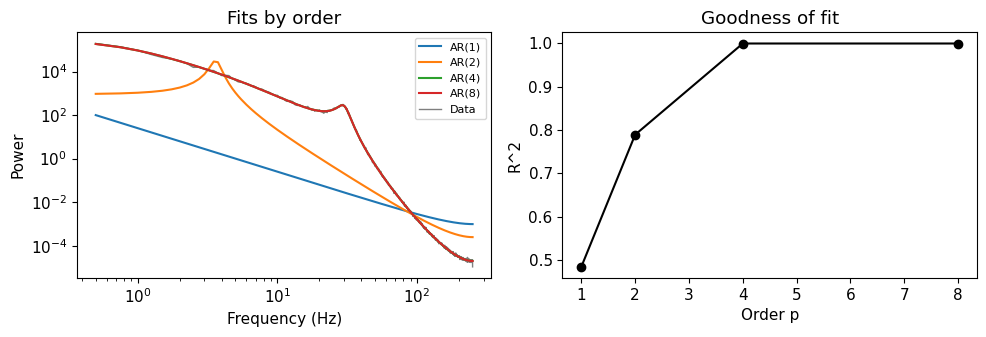

In [7]:
fig, axes = plt.subplots(1, 2)
for p, fit in fits.items():
    axes[0].loglog(freqs, fit.predict(), lw=1.5, label=f'AR({p})')
axes[0].loglog(freqs, powers, 'k', lw=1, alpha=.5, label='Data', zorder=0)
axes[0].set(xlabel='Frequency (Hz)', ylabel='Power', title='Fits by order')
axes[0].legend(fontsize=8)
axes[1].plot(list(fits), [f.rsq for f in fits.values()], 'o-', color='k')
axes[1].set(xlabel='Order p', ylabel='R^2', title='Goodness of fit')
fig.tight_layout();

## The lag domain

`ARACF` takes the same `order` argument and reports the same quantities.  Both
estimators fit the same coefficients, so their estimates agree when the model
is correct.  Disagreement indicates mis-specification in at least one
domain.

In [8]:
lags, corrs = compute_acf(sig, nlags=250)
acf_fit = ARACF(order=range(1, 11), fs=fs).fit(lags, corrs)
psd_fit = ARPSD(order=range(1, 11), fs=fs).fit(freqs, powers)

print(f'ARACF: order {acf_fit.order_}, tau = {acf_fit.tau * 1e3:.1f} ms')
print(f'ARPSD: order {psd_fit.order_}, tau = {psd_fit.tau * 1e3:.1f} ms')
print(f'true dominant relaxation: 200.0 ms')

ARACF: order 2, tau = 239.4 ms
ARPSD: order 4, tau = 223.2 ms
true dominant relaxation: 200.0 ms


## Models with no aperiodic mode

`tau` is NaN when every mode of the fitted model completes more than one cycle
before its envelope decays.  Such a model has an envelope decay and no
aperiodic timescale.  `tau_dominant` returns the decay time of the highest
importance mode, of either kind.

In [9]:
pure = ARPSD(order=2, fs=fs).fit(*compute_psd(
    osc.simulate(200., fs, np.random.default_rng(2)), fs,
    nperseg=int(4 * fs), f_range=(0.5, 250)))
print('tau          ', pure.tau)
print('tau_dominant ', f'{pure.tau_dominant * 1e3:.1f} ms')
print(repr(pure))

tau           nan
tau_dominant  100.3 ms
ARPSD(order=2, fs=500, tau=none (all modes rhythmic), tau_dominant=0.1003s, stationary=True)


Tutorial 3 converts fitted coefficients into timescales and frequencies.